In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

clean_df = pd.read_csv(
     r"C:\Users\ASUS\OneDrive\Desktop\ecommerce-delivery-operations-analysis/data/cleaned/supply_chain_cleaned.csv",
    parse_dates=[
        "order date (DateOrders)",
        "shipping date (DateOrders)"
    ]
)

print("Dataset shape:", clean_df.shape)

Dataset shape: (180519, 42)


In [2]:
clean_df.describe().T

,count,mean,min,25%,50%,75%,max,std
Days for shipping (real),180519.0,3.497654,0.0,2.0,3.0,5.0,6.0,1.623722
Days for shipment (scheduled),180519.0,2.931847,0.0,2.0,4.0,4.0,4.0,1.374449
Benefit per order,180519.0,21.974989,-4274.97998,7.0,31.52,64.800003,911.799988,104.433526
Sales per customer,180519.0,183.107609,7.49,104.379997,163.990005,247.399994,1939.98999,120.04367
Late_delivery_risk,180519.0,0.548291,0.0,0.0,1.0,1.0,1.0,0.497664
Category Id,180519.0,31.851451,2.0,18.0,29.0,45.0,76.0,15.640064
Customer Id,180519.0,6691.379495,1.0,3258.5,6457.0,9779.0,20757.0,4162.918106
Department Id,180519.0,5.44346,2.0,4.0,5.0,7.0,12.0,1.629246
Order Customer Id,180519.0,6691.379495,1.0,3258.5,6457.0,9779.0,20757.0,4162.918106
order date (DateOrders),180519,2016-06-12 17:47:04.669868544,2015-01-01 00:00:00,2015-09-21 13:49:00,2016-06-11 13:06:00,2017-03-01 08:42:00,2018-01-31 23:38:00,NaN


In [3]:
# Which shipping modes experience the most late-delivery risk?

shipping_analysis = (
    clean_df.groupby("Shipping Mode")
    .agg(
        Total_Orders=("Order Id", "count"),
        Late_Risk_Rate=("Late_delivery_risk", "mean"),
        Avg_Actual_Shipping_Days=(
            "Days for shipping (real)", "mean"
        ),
        Avg_Scheduled_Shipping_Days=(
            "Days for shipment (scheduled)", "mean"
        )
    )
    .reset_index()
)

shipping_analysis["Late_Risk_Percent"] = (
    shipping_analysis["Late_Risk_Rate"] * 100
).round(2)

shipping_analysis = shipping_analysis.drop(
    columns="Late_Risk_Rate"
)

shipping_analysis.sort_values(
    "Late_Risk_Percent", ascending=False
)

,Shipping Mode,Total_Orders,Avg_Actual_Shipping_Days,Avg_Scheduled_Shipping_Days,Late_Risk_Percent
0,First Class,27814,2.000000,1.0,95.32
2,Second Class,35216,3.990828,2.0,76.63
1,Same Day,9737,0.478279,0.0,45.74
3,Standard Class,107752,3.995907,4.0,38.07


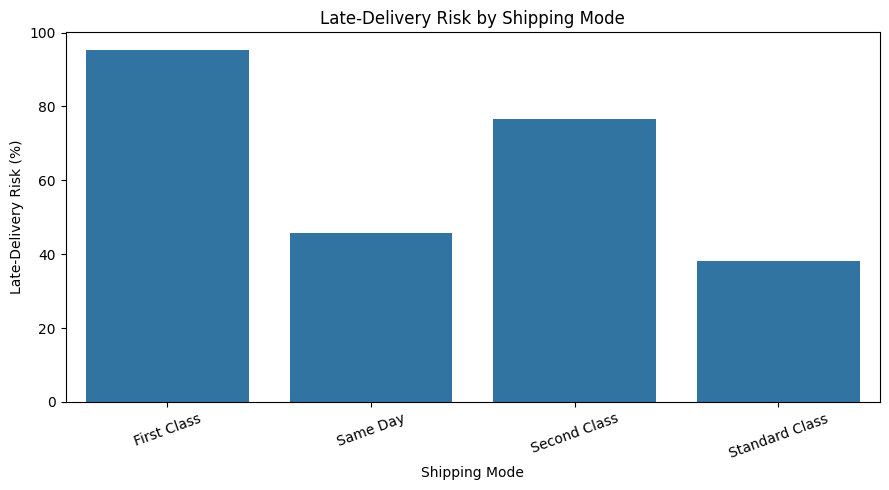

In [4]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=shipping_analysis,
    x="Shipping Mode",
    y="Late_Risk_Percent"
)

plt.title("Late-Delivery Risk by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Late-Delivery Risk (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [5]:
# Which product categories generate losses?

category_analysis = (
    clean_df.groupby("Category Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Order Profit Per Order", "sum"),
        Avg_Profit=("Order Profit Per Order", "mean"),
        Order_Count=("Order Id", "count")
    )
    .reset_index()
)

category_analysis.sort_values(
    "Total_Profit", ascending=True
)

,Category Name,Total_Sales,Total_Profit,Avg_Profit,Order_Count
41,Strength Training,5.489553e+04,332.310091,2.993785,111
7,CDs,3.059590e+03,383.850000,1.416421,271
1,As Seen on TV!,2.059794e+04,714.429980,10.506323,68
5,Books,1.258740e+04,883.010008,2.180272,405
43,Toys,6.104660e+03,900.710000,1.702665,529
2,Baby,1.222956e+04,1525.029992,7.367295,207
23,Golf Bags & Carts,1.036939e+04,1810.069992,29.673279,61
4,Basketball,2.709933e+04,1845.670003,27.547313,67
33,Men's Clothing,4.385680e+04,2006.039969,9.644423,208
45,Video Games,3.331050e+04,2717.519997,3.242864,838


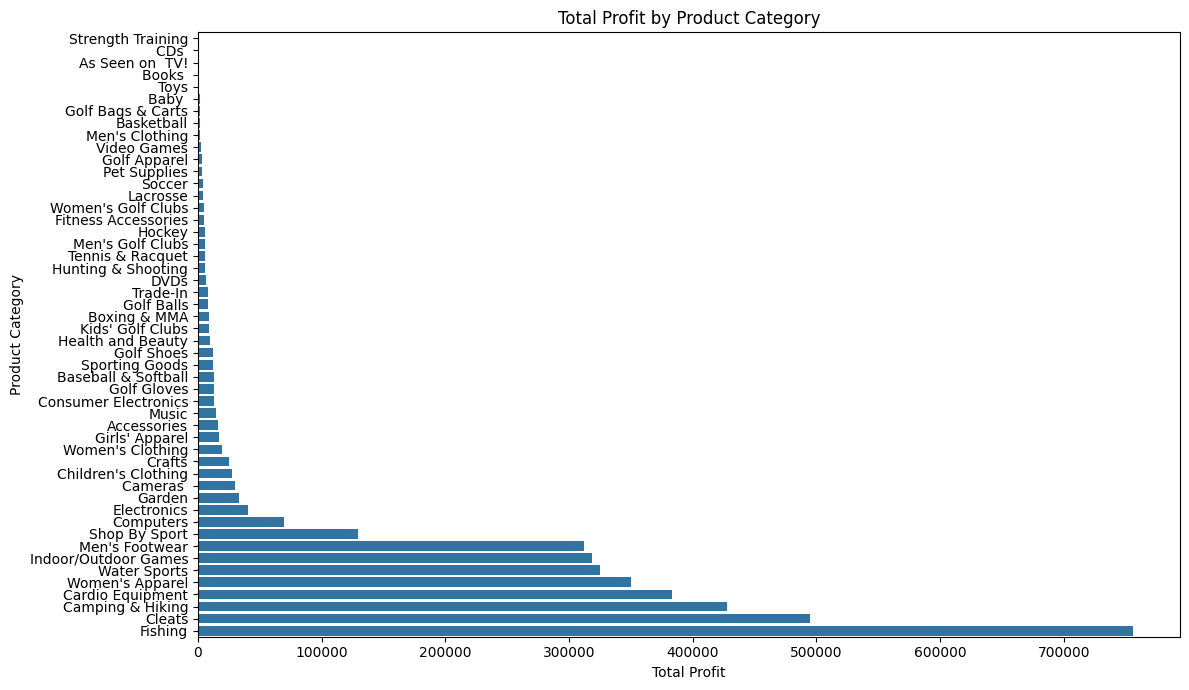

In [6]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=category_analysis.sort_values("Total_Profit"),
    x="Total_Profit",
    y="Category Name"
)

plt.title("Total Profit by Product Category")
plt.xlabel("Total Profit")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [7]:
# Are higher discounts associated with lower profit?
discount_analysis = (
    clean_df.groupby("Order Item Discount Rate")
    .agg(
        Avg_Profit=("Order Profit Per Order", "mean"),
        Total_Profit=("Order Profit Per Order", "sum"),
        Record_Count=("Order Id", "count")
    )
    .reset_index()
    .sort_values("Order Item Discount Rate")
)

discount_analysis.head(10)


,Order Item Discount Rate,Avg_Profit,Total_Profit,Record_Count
0,0.00,26.666574,267412.402338,10028
1,0.01,23.798760,238653.961066,10028
2,0.02,23.673829,237401.160814,10028
3,0.03,22.183212,222475.430184,10029
4,0.04,23.400469,234683.300468,10029
5,0.05,23.777867,238468.229398,10029
6,0.06,24.071789,241415.970777,10029
7,0.07,23.273000,233404.920995,10029
8,0.09,22.910502,229769.420426,10029
9,0.10,22.127961,221921.319172,10029


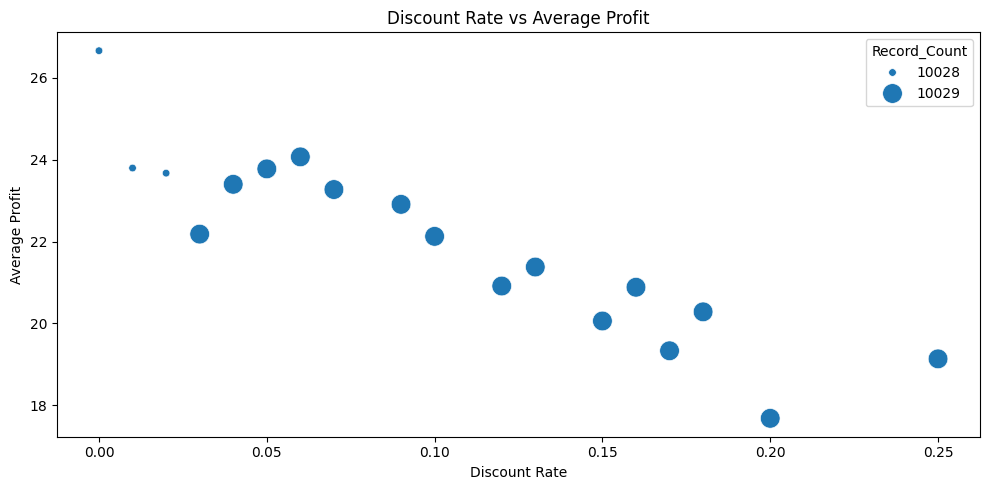

In [8]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=discount_analysis,
    x="Order Item Discount Rate",
    y="Avg_Profit",
    size="Record_Count",
    sizes=(30, 200)
)

plt.title("Discount Rate vs Average Profit")
plt.xlabel("Discount Rate")
plt.ylabel("Average Profit")
plt.tight_layout()
plt.show()

In [9]:
# How do sales and profit change over time?

clean_df["Order_Month"] = (
    clean_df["order date (DateOrders)"]
    .dt.to_period("M")
    .astype(str)
)

monthly_analysis = (
    clean_df.groupby("Order_Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Order Profit Per Order", "sum"),
        Order_Count=("Order Id", "count")
    )
    .reset_index()
)

monthly_analysis.head()

,Order_Month,Total_Sales,Total_Profit,Order_Count
0,2015-01,1.051590e+06,111660.740132,5322
1,2015-02,9.270099e+05,99140.660196,4729
2,2015-03,1.051254e+06,113778.210191,5362
3,2015-04,1.014463e+06,108083.679957,5126
4,2015-05,1.050478e+06,112147.900143,5357


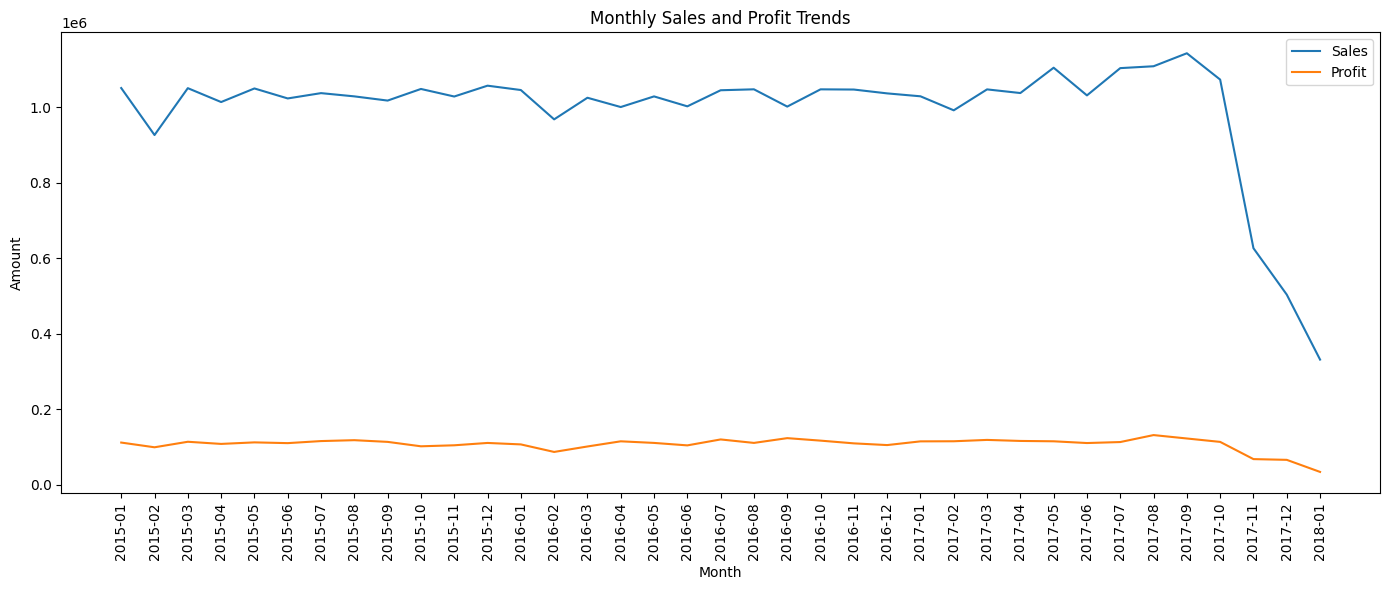

In [10]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_analysis["Order_Month"],
    monthly_analysis["Total_Sales"],
    label="Sales"
)

plt.plot(
    monthly_analysis["Order_Month"],
    monthly_analysis["Total_Profit"],
    label="Profit"
)

plt.title("Monthly Sales and Profit Trends")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()